# Heart Disease UCI — Exploratory Data Analysis

Run `python -m src.data` from the project root first. This notebook is part of the MLOps assignment; write your own interpretations below each chart.

In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('../data/raw/heart_disease.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/raw/heart_disease.csv')
df = pd.read_csv(DATA_PATH)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## Dataset shape and types

Record the shape and explain which columns are features and which is the target.

In [16]:
print('Shape:', df.shape)
display(df.info())
display(df.describe(include='all').T)

Shape: (303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


None

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Missing values

Discuss any columns with missing values and the preprocessing strategy used in the model pipeline.

In [17]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame('missing_count'))

,missing_count
ca,4
thal,2


## Target balance

Insert your interpretation of the class distribution and its implications for evaluation.

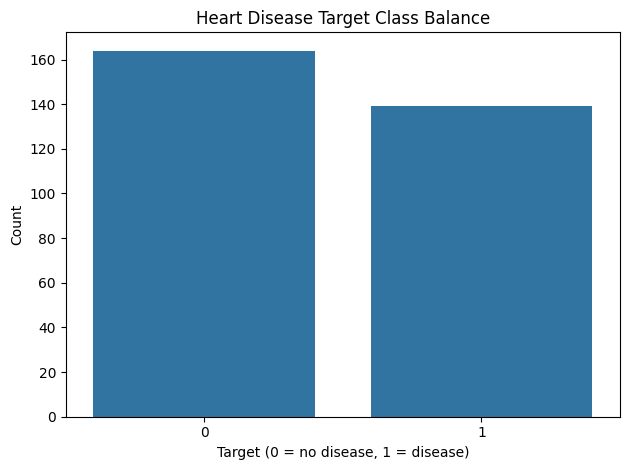

,proportion
target,
0,0.541254
1,0.458746


In [18]:
ax = sns.countplot(data=df, x='target')
ax.set_title('Heart Disease Target Class Balance')
ax.set_xlabel('Target (0 = no disease, 1 = disease)')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()
display(df['target'].value_counts(normalize=True).rename('proportion').to_frame())

## Feature distributions

Choose several clinically named variables and explain visible patterns without making causal or diagnostic claims.

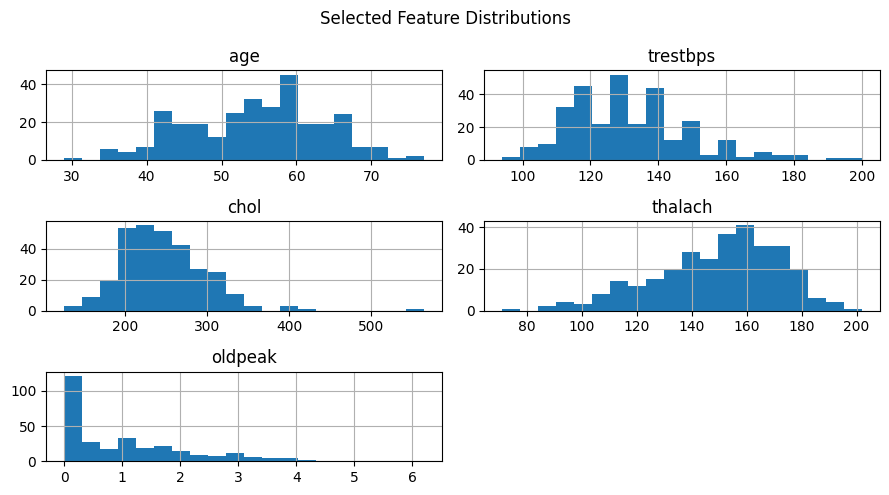

In [24]:
numeric_cols = [c for c in ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'] if c in df.columns]
df[numeric_cols].hist(figsize=(9, 5), bins=20)
plt.suptitle('Selected Feature Distributions')
plt.tight_layout()
plt.show()

## Correlation heatmap

Correlation is not causation. Explain what the heatmap suggests and what it cannot establish.

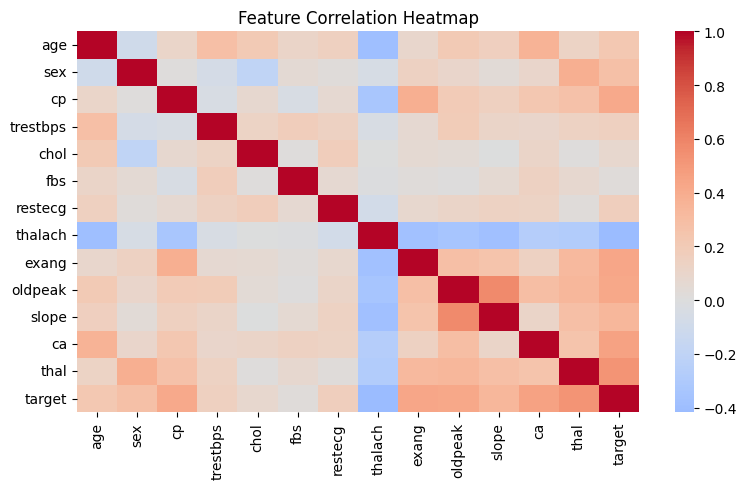

In [23]:
numeric_df = df.apply(pd.to_numeric, errors='coerce')
plt.figure(figsize=(8, 5))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

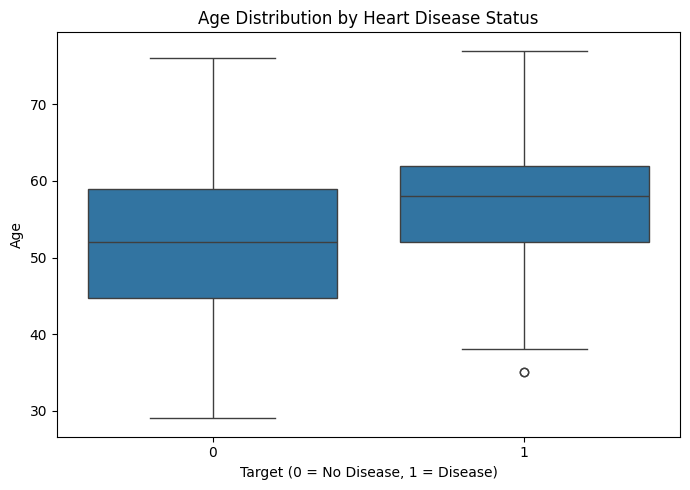

In [21]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x='target', y='age')

plt.title('Age Distribution by Heart Disease Status')
plt.xlabel('Target (0 = No Disease, 1 = Disease)')
plt.ylabel('Age')

plt.tight_layout()
plt.show()

## EDA Conclusions

- **Class balance:** The dataset contains 54.13% observations without heart disease and 45.87% with heart disease, indicating relatively balanced classes.
- **Missing values:** The ca feature contains 4 missing values, while thal contains 2. These missing values will be handled using most-frequent-value imputation in the preprocessing pipeline.
- **Feature distributions and correlations:** Histograms and the correlation heatmap help identify feature distributions, potential outliers, and relationships between numerical variables. The age boxplot shows a higher median age in the heart disease group.
- **Model evaluation:** Stratified sampling and metrics such as accuracy, precision, recall, and ROC-AUC will be used to evaluate model performance.

In [22]:

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values by column:")
print(df.isnull().sum())

# Check target distribution
print("\nTarget distribution:")
print(df["target"].value_counts(dropna=False))

print("\nTarget distribution in percentages:")
print((df["target"].value_counts(normalize=True, dropna=False) * 100).round(2))


Dataset shape: (303, 14)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values by column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope